## Oppgave 1

In [190]:
import numpy as np
import matplotlib.pyplot as plt

### 1a)
$\frac{\partial^2y}{\partial x^2} = -4*sin(2x),\ y(0)=0,\  y'(0)=2$

Siden høyresiden ikke avhenger av y kan vi integrere begge sider. det blir:

$\frac{\partial y}{\partial x} = 2*cos(2x)+A,\ y(0)=0,\  y'(0)=2$

Innsatt initialbetingelsen for $y'$ for vi:

$\frac{\partial y}{\partial x} = 2*cos(2x),\ y(0)=0$

Igjen avhenger ikke høyresiden av y så kan integrere.

$y(x) = sin(2x) + B,\ y(0)=0$

Innsatt initialbetingelsen for y.

$y(x) = sin(2x)$

### 1b)
Definer:

$\vec{y} = \left( \begin{matrix} y_1 \\ y_2 \end{matrix} \right) = \left( \begin{matrix} y \\ y' \end{matrix} \right)$

Da blir differensialligningen:

$\vec{y}' = \left( \begin{matrix} y_1' \\ y_2' \end{matrix} \right) = \left( \begin{matrix} y' \\ y'' \end{matrix} \right) = \left( \begin{matrix} y_2 \\ -4sin(2x) \end{matrix} \right)$

Og initialbetingelsen blir:

$\vec{y}(0) = \left( \begin{matrix} y(0) \\ y'(0) \end{matrix} \right) = \left( \begin{matrix} 0 \\ 2 \end{matrix} \right)$


### 1c)

Implementerer rungekutta som beskrever i prosjekt beskrivelsen

In [191]:
def RungeKutta32(
        x_init : float,
        x_end : float,
        y_init : np.ndarray[np.float64],
        f,
        h0 : float =0.1,
        tol : float = 1e-7,
        alpha : float = 0.8
                 ) -> tuple:
    
    # Vil bruke numpy array så gjør et gjett på størrelsen til x
    x  =  np.zeros(int(np.ceil((x_end-x_init)/h0)))
    y  =  np.zeros((int(x.size),len(y_init)))
    h  =  np.zeros_like(x)
    
    # Bruker intialbetingelsene for første iterasjon
    h[0] = h0
    x[0] = x_init
    y[0] = y_init
    z    = 0
    n    = 0
    m    = 0
    k1   = f(x_init,y_init)

    while x_end-x[n] > 0:
       
        # Gjør arrayet større i tilfellet at gjetningen på størreslen var for liten
        if len(x)==n+1:
            sizeInc = int(np.ceil((x_end-x[n])/h[n]))
            x = np.concatenate((x,np.zeros(sizeInc)))
            y = np.concatenate((y,np.zeros((sizeInc,len(y_init)))))
            h = np.concatenate((h,np.zeros(sizeInc)))

        
        h[n] = min(h[n],x_end-x[n]) # Sørger for at den treffer slutt verdien til x

        # Gjør en iterasjon av rungekutta
        k2 = f(x[n]+h[n]/2,y[n]+h[n]*k1/2)
        k3 = f(x[n]+3/4*h[n],y[n]+3/4*h[n]*k2)
        y[n+1] = (y[n]+h[n]/9*(2*k1+3*k2+4*k3))
        x[n+1] = (x[n]+h[n])
        k4 = f(x[n]+h[n],y[n+1])
        z = y[n]+h[n]/24*(7*k1+6*k2+8*k3+3*k4)
        err_est = np.linalg.norm(y[n+1]-z)
        if err_est<tol:
            h[n+1]=alpha*h[n]*(tol/err_est)**(1/3)
            n += 1
            k1 = k4
        else:
            h[n]=alpha*h[n]*(tol/err_est)**(1/3)
            m+=1
        
    
    # Fjerner nuller bakerst i arrayet i tilfellet array ble for stort
    x = np.trim_zeros(x,trim="b")
    y = np.trim_zeros(y,trim="b")
    h = np.trim_zeros(h,trim="b")


    return x, y, (n,h,m)

Definerer høyresiden av differensialligningen på formen funnet i 1b

In [192]:
def diff_func_1a(
        x : float,
        y : np.ndarray[np.float64]
    )  -> np.ndarray[np.float64]:

    out=np.zeros_like(y)

    out[0]=y[1]
    out[1]=-4*np.sin(2*x)

    return out

Kjører rungekutta og plotter resultatet. De se riktige ut

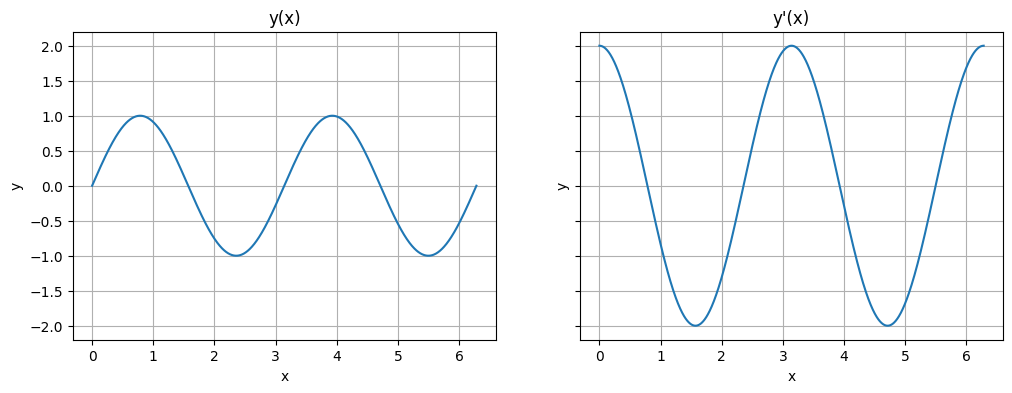

In [193]:
x_init = 0
x_end = 2*np.pi
y_init = np.array([0,2])


x , y , n= RungeKutta32(x_init,x_end,y_init,diff_func_1a,tol= 1e-7, alpha=0.8)


fig = plt.figure("Oppgave 1c", figsize=(12,4))
subplots = fig.subplots(1,2, sharey=True)
subplots[0].plot(x,y[:,0])
subplots[0].grid()
subplots[0].set_xlabel('x')
subplots[0].set_ylabel('y')
subplots[0].set_title('y(x)')

subplots[1].plot(x,y[:,1])
subplots[1].grid()
subplots[1].set_xlabel('x')
subplots[1].set_ylabel('y')
subplots[1].set_title("y'(x)")

plt.show()


Plotter steglengden $h$ som funksjon av x

1070


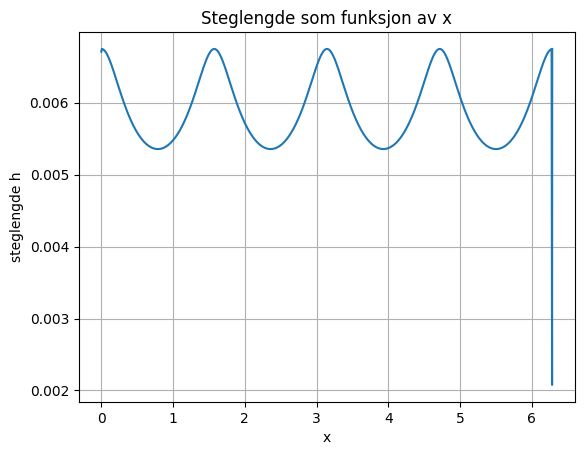

In [194]:
print(n[0])
plt.title("Steglengde som funksjon av x")
plt.plot(x,n[1])
plt.grid()
plt.xlabel("x")
plt.ylabel("steglengde h")
plt.show()

Steglengden er høyest ved røttene til funksjonen. Dette gir veldig mening ettersom det er der en sinus funksjon er mest linær, eller med andre ord der den dobbelt derivert er nærmest null. Tilsvarende er steglengden lavest ved ekstremalpunktene til løsningenen siden det er der absolutverdien av den dobbeltderiverte er høyest. Fallet i slutten av grafen kommer fra miniumsleddet som sørger for at den siste h-verdien treffer på $x_{end}$




Definerer den analytiske løsningen

In [195]:
def anal_solution(x):
    return np.sin(2*x)


Kjører rungekutta for flere verdier av toleransen, og plotter feilen som en funksjon av toleransen. Bruker 2-normen av differansen mellom analytisk og numersik løsning som feil estimat.

In [196]:
tols= np.logspace(0,-10,100)
error= np.zeros_like(tols)


for i in range(len(tols)):
    x , y , n= RungeKutta32(np.float64(x_init),x_end,y_init,diff_func_1a,tol = tols[i], alpha=0.8)
    
    error[i] = np.linalg.norm(y[:,0]-anal_solution(x))

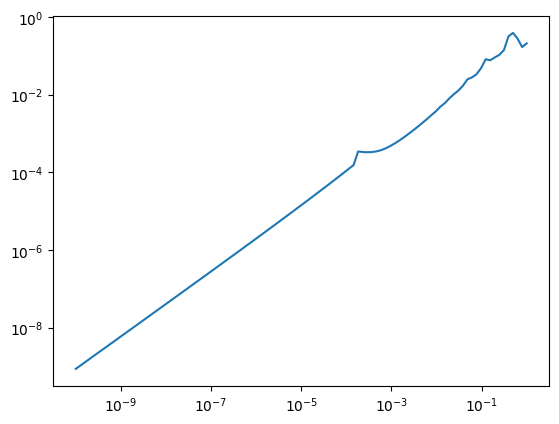

In [197]:
plt.figure("Error/tols")
plt.plot(tols,error)
plt.xscale("log")
plt.yscale("log")

For tilstrekklige 

In [198]:
alphas= np.linspace(0.1,1,100)
alphas[-1]=1
Iterations = np.zeros_like(alphas)
for i in range(len(alphas)):
    x , y , n= RungeKutta32(x_init,x_end,y_init,diff_func_1a, alpha=alphas[i])
    Iterations[i] = n[0]+ n[2]

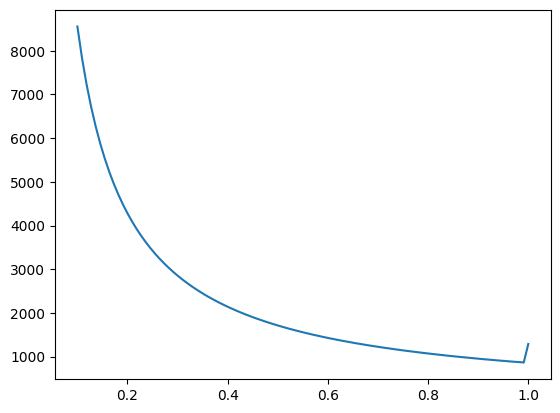

In [199]:
plt.figure("Iterations/alphas")
plt.plot(alphas, Iterations)
plt.show()

For fast steglengde vil antall iterasjoner være omvendt propsjonal med steglengden. Siden alhpa er proposjonal med steglengden i hvert steg vil sammenhengen mellom alpha og antall godkjente iterasjoner også være omvendt propsjonal. Dette gjenspeiles godt i simulation der grafen ligner en rasjonal funksjon. For lave alpha er antall forkastede iterasjoner svært lite i forhold til antall godkjente iterasjoner slik at at en bare ser effekten av den omvendte proposjonaliteten. Derimot for alpha som nærmer seg 1 vil antall forkastede iterasjoner øke drastisk, som observert på grafen. Dette er fordi ved høye alpha vil feilen alltid være i næreheten av toleranse grensen, slik at det skal lite til før et steg blir forkastet. Alpha lik 1 er altså dårlig for effektiviten til programmet, men samtidig vil det være gunstig å ha så høy alpha som mulig. 

# 1e

Implementerer sekant metoden

In [200]:
def sekantMetode(
        g, 
        z0 : float,
        z1 : float,
        tol : float,
) -> float:
    z = [z0,z1]
    i=1
    while abs(z[i]-z[i-1])>tol:
        z_new=(z[i-1]*g(z[i])-z[i]*g(z[i-1]))/(g(z[i])-g(z[i-1]))
        z.append(z_new)
        i+=1
    return z


Definerer funskjon og kjører sekant metoden på den.

[10000, 100000000, np.float64(1.2579523548052556), np.float64(-1.2592279680193), np.float64(-0.1750218122707619), np.float64(-0.44630638988516436), np.float64(-0.4570006334566943), np.float64(-0.4566243218014748)]


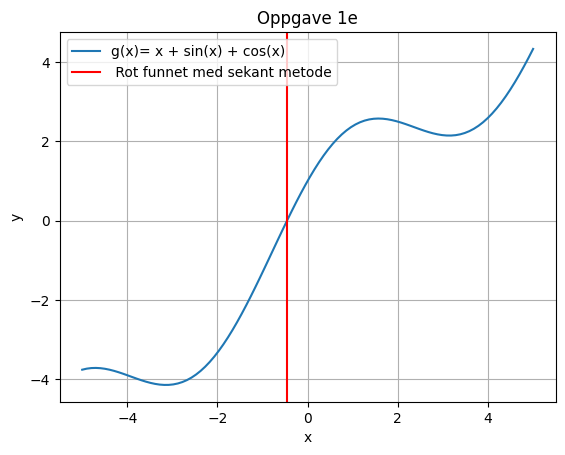

In [201]:
def test_g(x):
    return x + np.sin(x) + np.cos(x)

root = sekantMetode(test_g,10000,100000000,0.001)
print(root)
x=np.linspace(-5,5,100)
plt.figure("oppgave 1e")
plt.title("Oppgave 1e")
plt.plot(x,test_g(x), label = "g(x)= x + sin(x) + cos(x)")
plt.axvline(root[-1],0,1,color="r", label= " Rot funnet med sekant metode")
plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.legend()
plt.show()

Her er plottet av funksjonen sammen med nullpunktet funnet med sekanr

# 1f

Starter med å implementere skyte metoden. 

In [202]:
def BVP_solver(
        f,
        x_init : float,
        x_end : float,
        y_boundaries : tuple,
        b0 : float,
        b1 : float,
        tol : float = 1e-7,
) -> tuple:
    
    # Definerer først en funksjon som passer på formen til sekant metode løseren
    def rungef(b,x_init=x_init,x_end=x_end,y_boundaries=y_boundaries,f=f):
        y_init=np.array((y_boundaries[0],b))
        x,y,n = RungeKutta32(x_init,x_end,y_init,f,tol=tol)
        return y[:,0][-1]-y_boundaries[1] # Returnerer her differansen mellom y(x_end) for et gjett og grensebetingelsen til bvp
                                          # Dette blir null ved riktig gjett på initial betingelsen, så derfor kan sekant metoden løse for roten
    
    b_iterations = sekantMetode(rungef,b0,b1,tol) # Kjører sekant metoden på den nylig definerte funksjonen 
    y_init = np.array((y_boundaries[0],b_iterations[-1]))
    x,y,n = RungeKutta32(x_init,x_end,y_init,f,tol=tol)
    return x,y,n, b_iterations # Returnere siste iterasjon av y pluss et array med de forskjellig gjettene på initial betingelsen


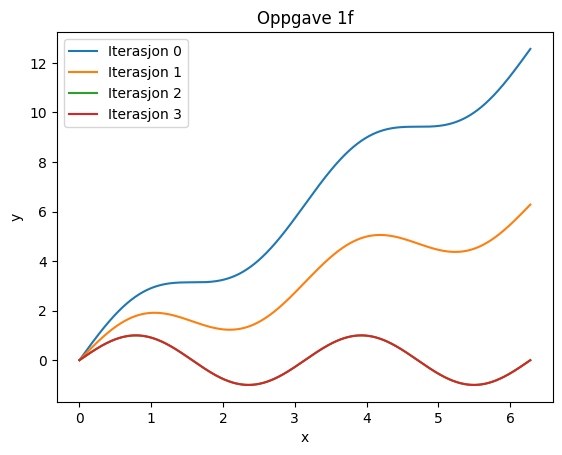

In [203]:
y_boundaries=(0,0)
b0=4
b1=3


result = BVP_solver(diff_func_1a,x_init,x_end,y_boundaries,b0,b1)

plt.figure("BVP solution 1f")
for i in range(len(result[3])):  
    y_init=np.array((y_boundaries[0],result[3][i]))
    x,y,n = RungeKutta32(x_init,x_end,y_init,diff_func_1a) 
    
    plt.plot(x,y[:,0], label = f"Iterasjon {i}")
plt.title("Oppgave 1f")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


Kan se at sekant metoden trenger kun en itersajon for å finne riktig initialbetingelse. Det er enda en iterasjon, men det er bare fordi sekant metoden trenger å gjøre en ekstra iterasjon for å sjekka at differansen mellom de to siste iterasjonene er tilstrekkelig liten. At sekant metoden kun bruker en iterasjon på å finne riktig initialbetingelse er også uavhengig av de første to gjettene, siden feilen i grensen vil være linært avhengig av feilen i gjettet for akkurat denne differensialligningen. 

# 1g

In [204]:
def diff_func_1g(
        x : float,
        y : np.ndarray[np.float64]
    )  -> np.ndarray[np.float64]:

    out=np.zeros_like(y)

    out[0]=y[1]
    out[1]=y[0] + np.sin(x)
    
    return out

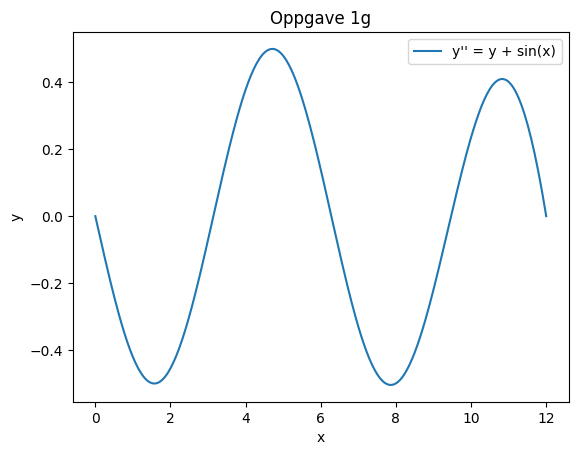

In [223]:
x_init_g = 0
x_end_g = 12
y_boundaries=(0,0)
b0=3
b1=2

result_g = BVP_solver(diff_func_1g,x_init_g,x_end_g,y_boundaries,b0,b1, tol=1e-6)


plt.figure("BVP solution 1g")
plt.plot(result_g[0],result_g[1][:,0], label = "y'' = y + sin(x)")
plt.title("Oppgave 1g")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

# 1h

In [224]:
def diff_func_1h(
        x : float,
        y : np.ndarray[np.float64]
    )  -> np.ndarray[np.float64]:

    out=np.zeros_like(y)

    out[0]=y[1]
    out[1]=y[0] + np.sin(x)
    
    return np.vstack(out)

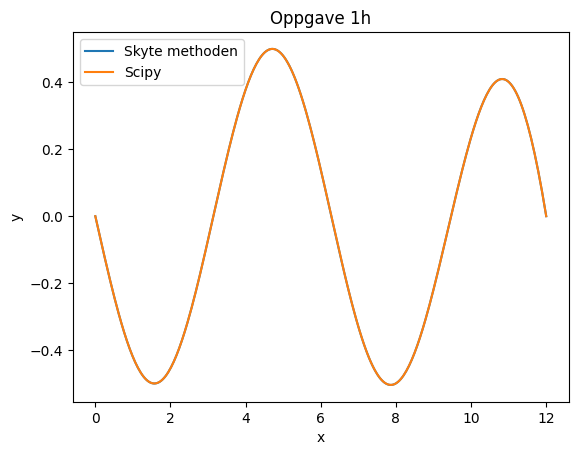

In [227]:
from scipy.integrate import solve_bvp

def y_bound(ya,yb):
    return np.array([ya[0],yb[0]])
x=np.linspace(x_init_g,x_end_g,10)
y_a = np.zeros((2, x.size))



res_a = solve_bvp(diff_func_1h,y_bound,x,y_a)
plt.figure("BVP solution 1h")
x_plot = result_g[0]
y_plot_a = res_a.sol(x_plot)[0]

import matplotlib.pyplot as plt
plt.plot(x_plot, result_g[1][:,0], label="Skyte methoden")
plt.plot(x_plot, y_plot_a, label='Scipy')

plt.title("Oppgave 1h")
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.show()

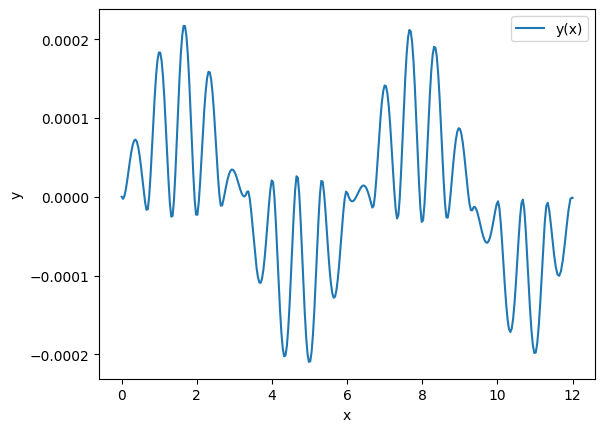

In [226]:
plt.plot(x_plot, y_plot_a-result_g[1][:,0], label='y(x)')
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.show()